# Benchmark Results Analysis: Multi-Agent Systems (MAS 1 – 4)

This notebook analyzes the benchmark evaluation results across all 4 Multi-Agent System configurations on the GAIA benchmark tasks:
- **MAS 1**: FDM Orchestrator + LLM Subagents (no think)
- **MAS 2**: LLM Orchestrator (no think) + LLM Subagents (no think)
- **MAS 3**: LLM Orchestrator (think) + LLM Subagents (no think)
- **MAS 4**: LLM Orchestrator (no think) + FDM Subagents (think on LLM args)

### Metrics Evaluated:
1. **Accuracy**: How many tasks were answered correctly for each MAS (overall and by Level 1 vs Level 2).
2. **Compute Time**: Time taken per task (mean, median, min, max, total runtime).
3. **Token Usage**: Token counts per task (LLM input/output, FDM input/output, and total tokens).
4. **Efficiency Trade-offs**: Visualizations comparing accuracy vs speed and accuracy vs token consumption.

In [ ]:
import os
import io
import glob
import json
import warnings
import contextlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



# Official GAIA scorer
from harness.utils.official_gaia_scorer import question_scorer
print('Libraries and GAIA scorer loaded successfully.')

Libraries and GAIA scorer loaded successfully.


## 1. Data Ingestion & Ground Truth Scoring
Load ground truth definitions from `tasks/tasks_benchmark_val_lvl1_2.json` and parse the task CSV logs under `results/mas_*/`.

In [2]:
# 1. Load Ground Truth
gt_path = 'tasks/tasks_benchmark_val_lvl1_2.json'
if not os.path.exists(gt_path):
    gt_path = 'tasks/tasks_benchmark_60.json'

with open(gt_path, 'r', encoding='utf-8') as f:
    ground_truth = json.load(f)

gt_map = {t['task_id']: t for t in ground_truth}
print(f'Loaded {len(gt_map)} benchmark tasks from {gt_path}.')

# 2. Multi-Agent Configurations
mas_configs = {
    'mas_1': 'MAS 1 (FDM Orch + LLM Sub)',
    'mas_2': 'MAS 2 (LLM Orch + LLM Sub)',
    'mas_3': 'MAS 3 (LLM Orch [Think] + LLM Sub)',
    'mas_4': 'MAS 4 (LLM Orch + FDM Sub)'
}

records = []

for mas_id, mas_label in mas_configs.items():
    csv_files = glob.glob(f'results/{mas_id}/mas_log_*.csv')
    for fpath in csv_files:
        task_id = os.path.basename(fpath).replace('mas_log_', '').replace('.csv', '')
        gt_item = gt_map.get(task_id, {})
        expected = str(gt_item.get('expected_answer', '')).strip()
        level = gt_item.get('level', gt_item.get('Level', 1))
        
        try:
            df = pd.read_csv(fpath)
        except Exception:
            continue
            
        if len(df) == 0:
            predicted = ''
            total_time = 0.0
            llm_in, llm_out, fdm_in, fdm_out = 0, 0, 0, 0
            steps = 0
        else:
            predicted = str(df.iloc[-1].get('response', '')).strip()
            total_time = float(df['compute_time_seconds'].fillna(0).sum()) if 'compute_time_seconds' in df else 0.0
            llm_in = int(df['llm_tkns_in'].fillna(0).sum()) if 'llm_tkns_in' in df else 0
            llm_out = int(df['llm_tkns_out'].fillna(0).sum()) if 'llm_tkns_out' in df else 0
            fdm_in = int(df['fdm_tkns_in'].fillna(0).sum()) if 'fdm_tkns_in' in df else 0
            fdm_out = int(df['fdm_tkns_out'].fillna(0).sum()) if 'fdm_tkns_out' in df else 0
            steps = len(df)
            
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                is_correct = bool(question_scorer(predicted, expected)) if expected else False
        except Exception:
            is_correct = False
            
        records.append({
            'mas': mas_id,
            'mas_label': mas_label,
            'task_id': task_id,
            'level': level,
            'expected_answer': expected,
            'predicted_answer': predicted,
            'is_correct': is_correct,
            'steps': steps,
            'time_seconds': total_time,
            'llm_tkns_in': llm_in,
            'llm_tkns_out': llm_out,
            'fdm_tkns_in': fdm_in,
            'fdm_tkns_out': fdm_out,
            'total_tokens': llm_in + llm_out + fdm_in + fdm_out
        })

df_all = pd.DataFrame(records)
print(f'Total parsed records: {len(df_all)} across {df_all["mas"].nunique()} MAS systems.')
df_all.head(5)

Loaded 139 benchmark tasks from tasks/tasks_benchmark_val_lvl1_2.json.
Total parsed records: 556 across 4 MAS systems.


,mas,mas_label,task_id,level,expected_answer,predicted_answer,is_correct,steps,time_seconds,llm_tkns_in,llm_tkns_out,fdm_tkns_in,fdm_tkns_out,total_tokens
0,mas_1,MAS 1 (FDM Orch + LLM Sub),023e9d44-96ae-4eed-b912-244ee8c3b994,2,8,9.50 dollars,False,14,10.354167,41473,364,796,0,42633
1,mas_1,MAS 1 (FDM Orch + LLM Sub),0383a3ee-47a7-41a4-b493-519bdefe0488,1,Rockhopper penguin,Groundhog,False,24,13.471974,19275,923,4106,0,24304
2,mas_1,MAS 1 (FDM Orch + LLM Sub),04a04a9b-226c-43fd-b319-d5e89743676f,2,41,The exact number of Nature articles published ...,False,24,40.065476,16542,4872,4139,0,25553
3,mas_1,MAS 1 (FDM Orch + LLM Sub),05407167-39ec-4d3a-a234-73a9120c325d,2,Format Document,remove extra lines,False,30,14.443534,19823,863,3386,0,24072
4,mas_1,MAS 1 (FDM Orch + LLM Sub),076c8171-9b3b-49b9-a477-244d2a532826,2,Finance,Carnivore Loan Specialists,False,5,1.358545,2753,74,746,0,3573


## 2. Correctness & Accuracy Analysis
Evaluating the number of correct tasks and accuracy percentage for each MAS (overall and across Level 1 & Level 2).

In [3]:
accuracy_stats = []

for mas_id in mas_configs.keys():
    sub = df_all[df_all['mas'] == mas_id]
    total_tasks = len(sub)
    correct_tasks = sub['is_correct'].sum()
    acc_overall = (correct_tasks / total_tasks * 100) if total_tasks > 0 else 0.0
    
    # Level 1
    l1 = sub[sub['level'] == 1]
    l1_corr = l1['is_correct'].sum()
    l1_acc = (l1_corr / len(l1) * 100) if len(l1) > 0 else 0.0
    
    # Level 2
    l2 = sub[sub['level'] == 2]
    l2_corr = l2['is_correct'].sum()
    l2_acc = (l2_corr / len(l2) * 100) if len(l2) > 0 else 0.0
    
    accuracy_stats.append({
        'Configuration': mas_configs[mas_id],
        'Tasks Done': total_tasks,
        'Correct Tasks': int(correct_tasks),
        'Overall Accuracy (%)': round(acc_overall, 2),
        'L1 Correct': f'{l1_corr}/{len(l1)}',
        'L1 Accuracy (%)': round(l1_acc, 2),
        'L2 Correct': f'{l2_corr}/{len(l2)}',
        'L2 Accuracy (%)': round(l2_acc, 2),
    })

df_accuracy = pd.DataFrame(accuracy_stats)
df_accuracy

,Configuration,Tasks Done,Correct Tasks,Overall Accuracy (%),L1 Correct,L1 Accuracy (%),L2 Correct,L2 Accuracy (%)
0,MAS 1 (FDM Orch + LLM Sub),139,9,6.47,4/53,7.55,5/86,5.81
1,MAS 2 (LLM Orch + LLM Sub),139,9,6.47,5/53,9.43,4/86,4.65
2,MAS 3 (LLM Orch [Think] + LLM Sub),139,5,3.60,3/53,5.66,2/86,2.33
3,MAS 4 (LLM Orch + FDM Sub),139,7,5.04,4/53,7.55,3/86,3.49


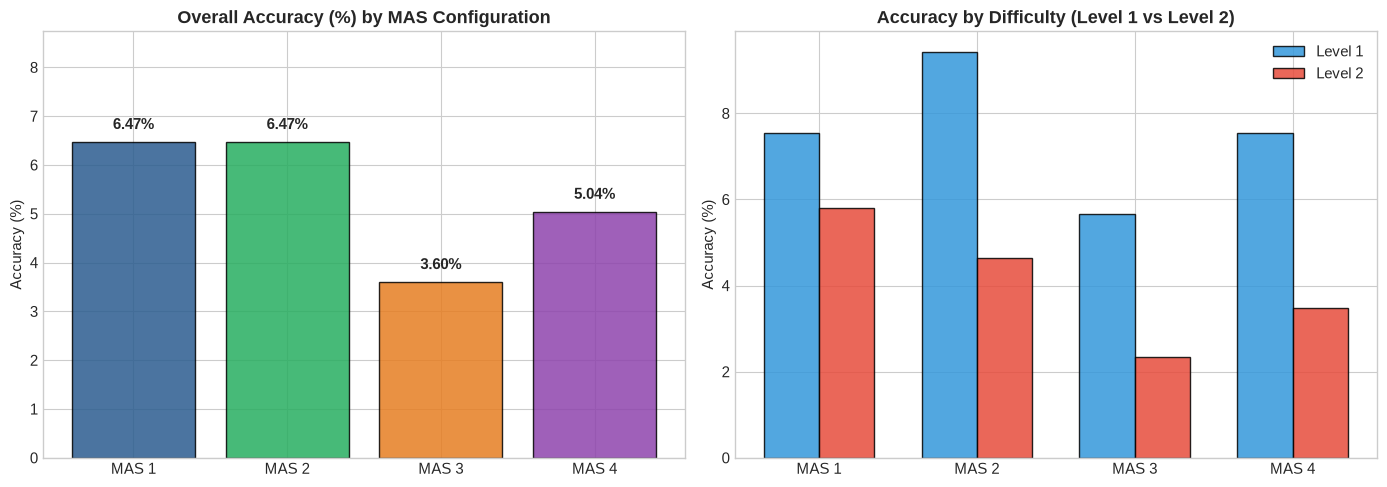

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Overall Accuracy Bar Chart
x_labels = [f'MAS {i+1}' for i in range(len(df_accuracy))]
bars = axes[0].bar(
    x_labels,
    df_accuracy['Overall Accuracy (%)'],
    color=['#2b5c8f', '#27ae60', '#e67e22', '#8e44ad'],
    edgecolor='black',
    alpha=0.85
)
axes[0].set_title('Overall Accuracy (%) by MAS Configuration', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(0, max(df_accuracy['Overall Accuracy (%)']) * 1.35)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.2, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

# Plot 2: Level 1 vs Level 2 Accuracy
x = np.arange(len(df_accuracy))
width = 0.35
r1 = axes[1].bar(x - width/2, df_accuracy['L1 Accuracy (%)'], width, label='Level 1', color='#3498db', edgecolor='black', alpha=0.85)
r2 = axes[1].bar(x + width/2, df_accuracy['L2 Accuracy (%)'], width, label='Level 2', color='#e74c3c', edgecolor='black', alpha=0.85)
axes[1].set_title('Accuracy by Difficulty (Level 1 vs Level 2)', fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(x_labels)
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Compute Time per Task Analysis
Summary statistics and distributions of compute execution times (in seconds) per task across configurations.

In [5]:
time_stats = []

for mas_id in mas_configs.keys():
    sub = df_all[df_all['mas'] == mas_id]['time_seconds']
    time_stats.append({
        'Configuration': mas_configs[mas_id],
        'Mean Time (s)': round(sub.mean(), 2),
        'Median Time (s)': round(sub.median(), 2),
        'Std Dev (s)': round(sub.std(), 2),
        'Min Time (s)': round(sub.min(), 2),
        'Max Time (s)': round(sub.max(), 2),
        'Total Time (min)': round(sub.sum() / 60, 2)
    })

df_time = pd.DataFrame(time_stats)
df_time

,Configuration,Mean Time (s),Median Time (s),Std Dev (s),Min Time (s),Max Time (s),Total Time (min)
0,MAS 1 (FDM Orch + LLM Sub),7.52,8.22,5.47,0.20,40.07,17.42
1,MAS 2 (LLM Orch + LLM Sub),3.27,0.70,4.09,0.23,20.55,7.58
2,MAS 3 (LLM Orch [Think] + LLM Sub),4.66,0.70,7.47,0.23,57.51,10.80
3,MAS 4 (LLM Orch + FDM Sub),17.72,9.83,19.84,0.18,93.01,41.06


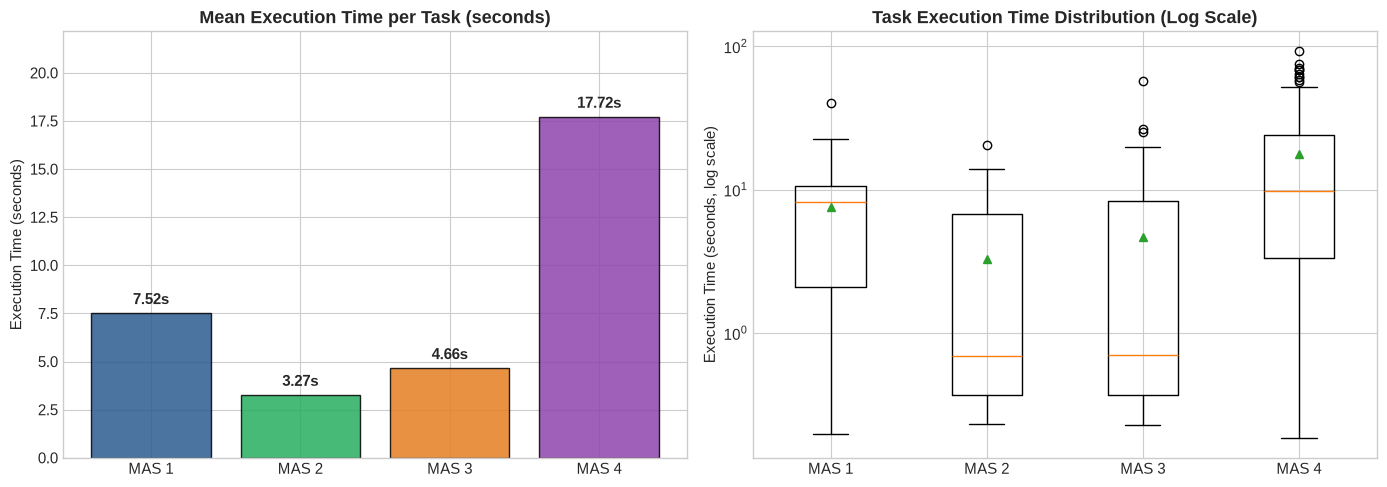

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Average Time per Task
bars = axes[0].bar(
    x_labels,
    df_time['Mean Time (s)'],
    color=['#2b5c8f', '#27ae60', '#e67e22', '#8e44ad'],
    edgecolor='black',
    alpha=0.85
)
axes[0].set_title('Mean Execution Time per Task (seconds)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Execution Time (seconds)')
axes[0].set_ylim(0, max(df_time['Mean Time (s)']) * 1.25)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f'{yval:.2f}s', ha='center', va='bottom', fontweight='bold')

# Plot 2: Boxplot of Execution Times per Task (log scale)
time_data = [df_all[df_all['mas'] == m]['time_seconds'].values for m in mas_configs.keys()]
axes[1].boxplot(time_data, tick_labels=x_labels, showmeans=True)
axes[1].set_title('Task Execution Time Distribution (Log Scale)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Execution Time (seconds, log scale)')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

## 4. Token Count per Task Analysis
Detailed breakdown of tokens consumed per task, categorized by LLM input, LLM output, and FDM tokens.

In [7]:
token_stats = []

for mas_id in mas_configs.keys():
    sub = df_all[df_all['mas'] == mas_id]
    token_stats.append({
        'Configuration': mas_configs[mas_id],
        'Mean Tokens / Task': round(sub['total_tokens'].mean(), 1),
        'Median Tokens / Task': round(sub['total_tokens'].median(), 1),
        'Mean LLM In / Task': round(sub['llm_tkns_in'].mean(), 1),
        'Mean LLM Out / Task': round(sub['llm_tkns_out'].mean(), 1),
        'Total LLM In': int(sub['llm_tkns_in'].sum()),
        'Total LLM Out': int(sub['llm_tkns_out'].sum()),
        'Total FDM Tokens': int(sub['fdm_tkns_in'].sum() + sub['fdm_tkns_out'].sum()),
        'Total Benchmark Tokens': int(sub['total_tokens'].sum())
    })

df_tokens = pd.DataFrame(token_stats)
df_tokens

,Configuration,Mean Tokens / Task,Median Tokens / Task,Mean LLM In / Task,Mean LLM Out / Task,Total LLM In,Total LLM Out,Total FDM Tokens,Total Benchmark Tokens
0,MAS 1 (FDM Orch + LLM Sub),16344.3,16714.0,14315.9,451.0,1989904,62695,219254,2271853
1,MAS 2 (LLM Orch + LLM Sub),7652.9,861.0,7459.6,193.3,1036882,26874,0,1063756
2,MAS 3 (LLM Orch [Think] + LLM Sub),12190.5,861.0,7059.7,259.0,981300,36003,677183,1694486
3,MAS 4 (LLM Orch + FDM Sub),53646.0,29989.0,27799.2,780.0,3864087,108424,3484279,7456790


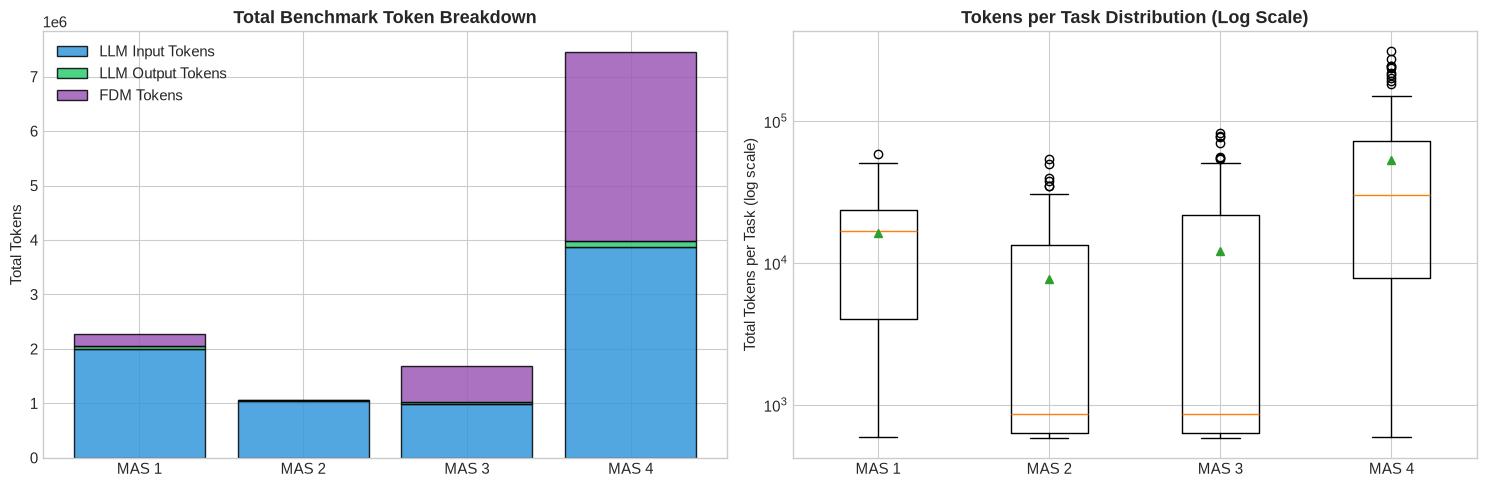

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Stacked Bar Chart of Token Composition
llm_in = [df_all[df_all['mas'] == m]['llm_tkns_in'].sum() for m in mas_configs.keys()]
llm_out = [df_all[df_all['mas'] == m]['llm_tkns_out'].sum() for m in mas_configs.keys()]
fdm_tok = [df_all[df_all['mas'] == m]['fdm_tkns_in'].sum() + df_all[df_all['mas'] == m]['fdm_tkns_out'].sum() for m in mas_configs.keys()]

axes[0].bar(x_labels, llm_in, label='LLM Input Tokens', color='#3498db', edgecolor='black', alpha=0.85)
axes[0].bar(x_labels, llm_out, bottom=llm_in, label='LLM Output Tokens', color='#2ecc71', edgecolor='black', alpha=0.85)
axes[0].bar(x_labels, fdm_tok, bottom=np.array(llm_in) + np.array(llm_out), label='FDM Tokens', color='#9b59b6', edgecolor='black', alpha=0.85)
axes[0].set_title('Total Benchmark Token Breakdown', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Total Tokens')
axes[0].legend()

# Plot 2: Boxplot of Tokens per Task (Log Scale)
tok_data = [df_all[df_all['mas'] == m]['total_tokens'].values for m in mas_configs.keys()]
axes[1].boxplot(tok_data, tick_labels=x_labels, showmeans=True)
axes[1].set_title('Tokens per Task Distribution (Log Scale)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Total Tokens per Task (log scale)')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

## 5. Efficiency & Pareto Trade-offs
Cross-analyzing accuracy versus speed (time) and accuracy versus cost (tokens) across the 4 systems.

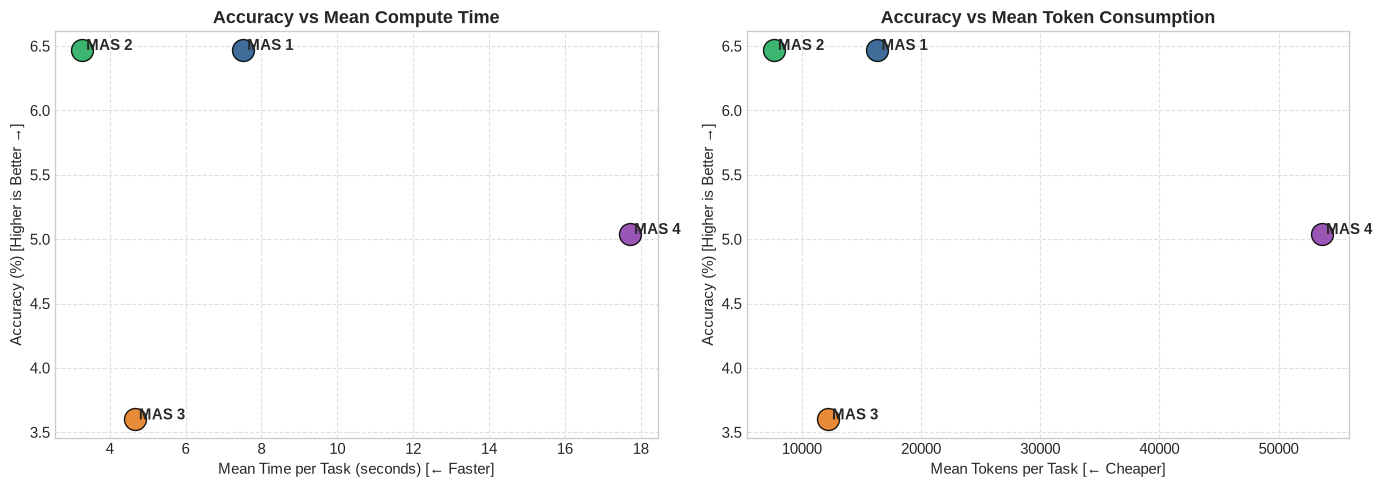

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mean_times = [df_all[df_all['mas'] == m]['time_seconds'].mean() for m in mas_configs.keys()]
mean_tokens = [df_all[df_all['mas'] == m]['total_tokens'].mean() for m in mas_configs.keys()]
accuracies = df_accuracy['Overall Accuracy (%)'].values
colors = ['#2b5c8f', '#27ae60', '#e67e22', '#8e44ad']

# Plot 1: Accuracy vs Mean Compute Time
for i, name in enumerate(x_labels):
    axes[0].scatter(mean_times[i], accuracies[i], s=250, color=colors[i], edgecolors='black', label=name, alpha=0.9)
    axes[0].annotate(f' {name}', (mean_times[i], accuracies[i]), fontsize=11, fontweight='bold')
axes[0].set_title('Accuracy vs Mean Compute Time', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mean Time per Task (seconds) [← Faster]')
axes[0].set_ylabel('Accuracy (%) [Higher is Better →]')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Accuracy vs Mean Token Consumption
for i, name in enumerate(x_labels):
    axes[1].scatter(mean_tokens[i], accuracies[i], s=250, color=colors[i], edgecolors='black', label=name, alpha=0.9)
    axes[1].annotate(f' {name}', (mean_tokens[i], accuracies[i]), fontsize=11, fontweight='bold')
axes[1].set_title('Accuracy vs Mean Token Consumption', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Mean Tokens per Task [← Cheaper]')
axes[1].set_ylabel('Accuracy (%) [Higher is Better →]')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 6. Export Detailed Task-by-Task Comparison
Save the complete per-task dataset for external reporting or deeper inspection.

In [10]:
output_csv = 'results/benchmark_task_analysis.csv'
df_all.to_csv(output_csv, index=False)
print(f'Detailed task-level results saved to: {output_csv}')

# Summary of correctly answered tasks
df_correct = df_all[df_all['is_correct']][['mas', 'task_id', 'level', 'expected_answer', 'predicted_answer', 'time_seconds', 'total_tokens']]
print(f'Total correct task occurrences across all 4 systems: {len(df_correct)}')
df_correct.head(10)

Detailed task-level results saved to: results/benchmark_task_analysis.csv
Total correct task occurrences across all 4 systems: 30


,mas,task_id,level,expected_answer,predicted_answer,time_seconds,total_tokens
22,mas_1,23dd907f-1261-4488-b21c-e9185af91d5e,1,2,2,10.662381,17741
30,mas_1,33d8ea3b-6c6b-4ff1-803d-7e270dea8a57,2,2,2,3.460567,8921
41,mas_1,4b650a35-8529-4695-89ed-8dc7a500a498,1,Guava,Guava,0.198248,602
43,mas_1,4d0aa727-86b1-406b-9b33-f870dd14a4a5,2,1 in 3,1 in 3,1.219312,3171
53,mas_1,5cfb274c-0207-4aa7-9575-6ac0bd95d9b2,1,No,No,1.344440,2844
60,mas_1,67e8878b-5cef-4375-804e-e6291fdbe78a,2,Hotels,Hotels,1.292330,3191
72,mas_1,7cc4acfa-63fd-4acc-a1a1-e8e529e0a97f,2,Wharvton,Wharvton,7.628144,19478
126,mas_1,e2d69698-bc99-4e85-9880-67eaccd66e6c,2,Michele Fitzgerald,Michele Fitzgerald,1.415824,2659
130,mas_1,ec09fa32-d03f-4bf8-84b0-1f16922c3ae4,1,3,3,0.343347,1368
169,mas_2,33d8ea3b-6c6b-4ff1-803d-7e270dea8a57,2,2,2,3.495754,9066
